In [1]:
import osmnx as ox
import matplotlib.pyplot as plt

place = "Kazan, Russia"

In [2]:
tags = {"natural": "water", "waterway": ["river", "stream", "canal"]}
water = ox.features_from_place(place, tags=tags)
print("Скачано объектов:", len(water))

Скачано объектов: 430


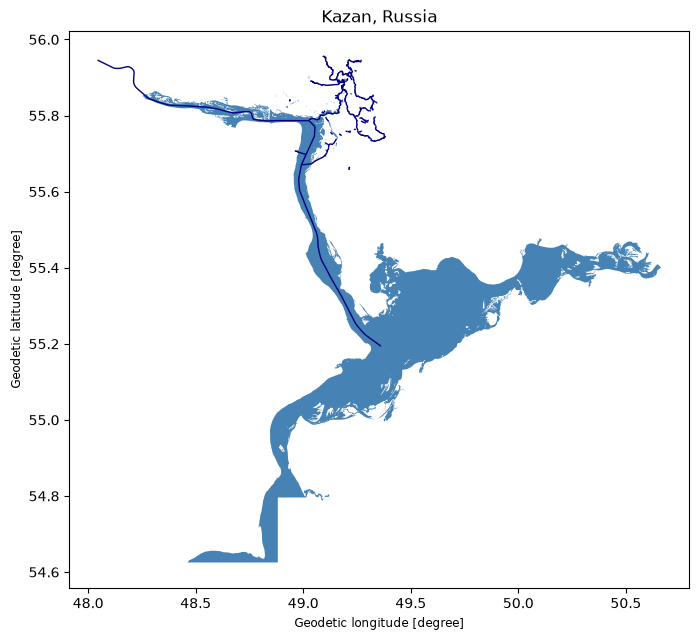

In [3]:
water = water.reset_index(drop=True)
cols = [c for c in ["name", "natural", "waterway"] if c in water.columns]
water = water[cols + ["geometry"]]

lakes = water[water.geometry.type.isin(["Polygon", "MultiPolygon"])]
rivers = water[water.geometry.type.isin(["LineString", "MultiLineString"])]

fig, ax = plt.subplots(figsize=(8, 8))
lakes.plot(ax=ax, color="steelblue")
rivers.plot(ax=ax, color="navy", linewidth=1)
ax.set_title(place)
plt.show()

In [4]:
lakes.to_file("water.gpkg", layer="lakes", driver="GPKG")
rivers.to_file("water.gpkg", layer="rivers", driver="GPKG")
print("Водоёмов:", len(lakes), "Рек и ручьёв:", len(rivers))

Водоёмов: 284 Рек и ручьёв: 146


In [5]:
import geopandas as gpd

lakes = gpd.read_file("water.gpkg", layer="lakes")
rivers = gpd.read_file("water.gpkg", layer="rivers")

crs = lakes.estimate_utm_crs()
lakes_m = lakes.to_crs(crs)
rivers_m = rivers.to_crs(crs)

area_km2 = lakes_m.union_all().area / 1e6
length_km = rivers_m.length.sum() / 1000

print("Система координат:", crs)
print("Площадь водоёмов, км²:", round(area_km2, 1))
print("Длина рек и ручьёв, км:", round(length_km, 1))

Система координат: EPSG:32639
Площадь водоёмов, км²: 2376.4
Длина рек и ручьёв, км: 336.7


In [6]:
lakes_m["area_km2"] = lakes_m.area / 1e6
top = lakes_m.sort_values("area_km2", ascending=False).head(5)
print(top[["name", "area_km2"]])

                          name     area_km2
0   Куйбышевское водохранилище  2361.264570
11                     Казанка     7.416943
4                Средний Кабан     1.282013
3                          NaN     1.078376
1                          NaN     0.993884


In [7]:
name_res = "Куйбышевское водохранилище"
reservoir = lakes_m[lakes_m["name"] == name_res]
others = lakes_m[lakes_m["name"] != name_res]

print("Куйбышевское водохранилище, км²:", round(reservoir.union_all().area / 1e6, 1))
print("Остальные водоёмы, км²:", round(others.union_all().area / 1e6, 1))
print("Число остальных водоёмов:", len(others))

Куйбышевское водохранилище, км²: 2361.3
Остальные водоёмы, км²: 15.2
Число остальных водоёмов: 283


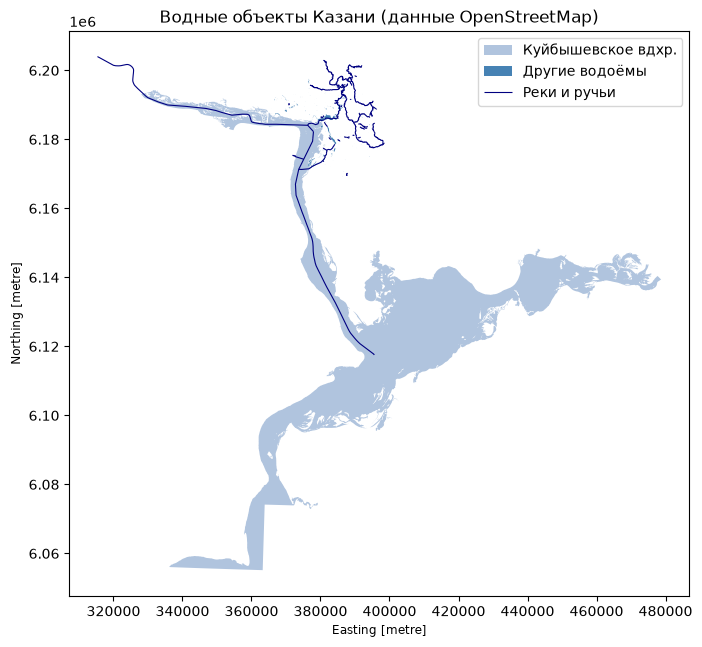

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))
reservoir.plot(ax=ax, color="lightsteelblue", label="Куйбышевское вдхр.")
others.plot(ax=ax, color="steelblue", label="Другие водоёмы")
rivers_m.plot(ax=ax, color="navy", linewidth=0.8, label="Реки и ручьи")
ax.set_title("Водные объекты Казани (данные OpenStreetMap)")
ax.legend()
plt.savefig("kazan_water.png", dpi=200, bbox_inches="tight")
plt.show()

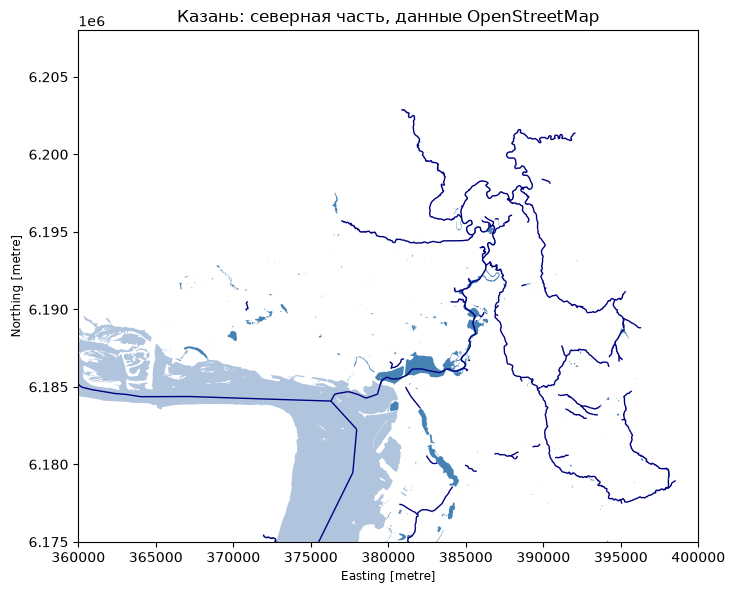

In [9]:
fig, ax = plt.subplots(figsize=(8, 8))
reservoir.plot(ax=ax, color="lightsteelblue")
others.plot(ax=ax, color="steelblue")
rivers_m.plot(ax=ax, color="navy", linewidth=1)

ax.set_xlim(360000, 400000)
ax.set_ylim(6175000, 6208000)
ax.set_title("Казань: северная часть, данные OpenStreetMap")

plt.savefig("kazan_water_zoom.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
kaban = lakes_m[lakes_m["name"].fillna("").str.contains("Кабан")]
print(kaban[["name", "area_km2"]])


             name  area_km2
4   Средний Кабан  1.282013
6    Нижний Кабан  0.480387
26  Верхний Кабан  0.277205


  показатель     фон   кабан  во сколько раз выше
0        ХПК  22.400   57.00             2.544643
1    Аммоний   0.050    0.36             7.200000
2   Сульфаты   1.752  349.00           199.200913
3    Хлориды   8.600  117.96            13.716279


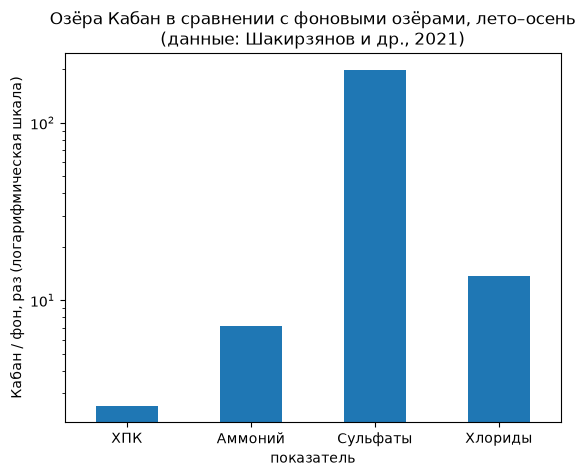

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame({
    "показатель": ["ХПК", "Аммоний", "Сульфаты", "Хлориды"],
    "фон": [22.4, 0.05, 1.752, 8.60],        # Ковалинское и Архиерейское
    "кабан": [57, 0.36, 349, 117.96],        # Средний и Нижний Кабан
})

data["во сколько раз выше"] = data["кабан"] / data["фон"]
print(data)

ax = data.plot.bar(x="показатель", y="во сколько раз выше", legend=False, logy=True)
ax.set_ylabel("Кабан / фон, раз (логарифмическая шкала)")
ax.set_title("Озёра Кабан в сравнении с фоновыми озёрами, лето–осень\n(данные: Шакирзянов и др., 2021)")
plt.xticks(rotation=0)
plt.savefig("kaban_vs_background.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
ax.bar_label(ax.containers[0], fmt="%.1f×")

[Text(0, 0, '2.5×'),
 Text(0, 0, '7.2×'),
 Text(0, 0, '199.2×'),
 Text(0, 0, '13.7×')]

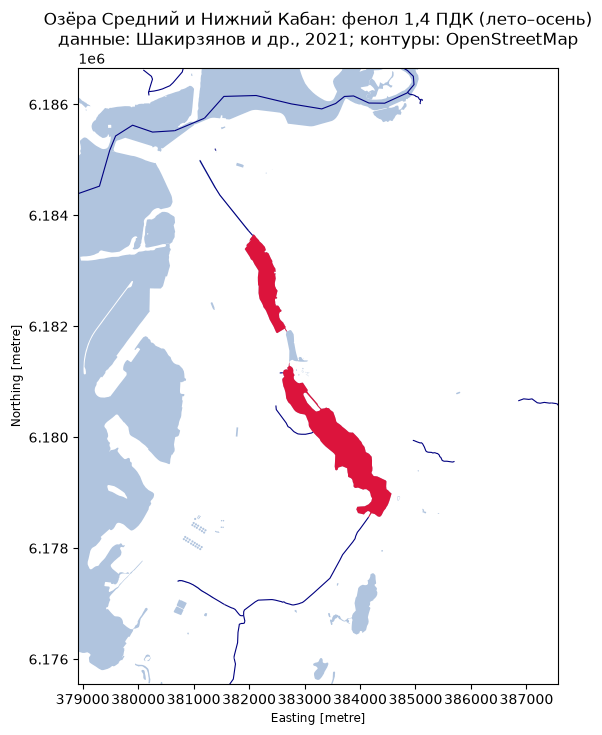

In [13]:
import matplotlib.pyplot as plt

kaban = lakes_m[lakes_m["name"].fillna("").str.contains("Средний Кабан|Нижний Кабан")]
minx, miny, maxx, maxy = kaban.total_bounds
pad = 3000  # поле вокруг озёр, метры

fig, ax = plt.subplots(figsize=(8, 8))
lakes_m.plot(ax=ax, color="lightsteelblue")
rivers_m.plot(ax=ax, color="navy", linewidth=0.8)
kaban.plot(ax=ax, color="crimson")

ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_title("Озёра Средний и Нижний Кабан: фенол 1,4 ПДК (лето–осень)\nданные: Шакирзянов и др., 2021; контуры: OpenStreetMap")

plt.savefig("kaban_phenol_map.png", dpi=200, bbox_inches="tight")
plt.show()

# Water bodies of Kazan and the Kaban lakes

**Data.** Water body outlines: OpenStreetMap (© OpenStreetMap contributors), downloaded with osmnx.
Hydrochemical indicators: Shakirzyanov A.M., Petrova D.I., Sofinskaya O.A. (2021),
Georesursy, 23(4), 70–75 (2014–2020 averages).

**What was done.**
- Downloaded and cleaned the water bodies of Kazan (lakes and rivers).
- Calculated areas and lengths in a metric projection (EPSG:32639).
- Treated the Kuibyshev Reservoir separately: the city boundary includes part of it
  and would distort the total. Other water bodies: [X] km².
- Compared the Kaban lakes with background lakes (summer–autumn averages).
- Mapped the Kaban lakes with phenol exceeding the maximum permissible concentration (1.4 MPC).

**Limitations.**
- Pollution values are lake-wide averages, not point measurements.
- Water bodies without data in the paper are shown as "no data", not as clean.
- High sulfate content is attributed by the authors to local geology, not necessarily pollution.

In [14]:
lakes_out = lakes_m.copy()
is_kaban = lakes_out["name"].fillna("").str.contains("Средний Кабан|Нижний Кабан")

lakes_out["phenol_pdk"] = float("nan")      # для остальных водоёмов данных нет
lakes_out.loc[is_kaban, "phenol_pdk"] = 1.4  # лето–осень, 2014–2020

lakes_out = lakes_out[["name", "area_km2", "phenol_pdk", "geometry"]]
lakes_out.to_file("kaban_pollution.gpkg", layer="lakes_pollution", driver="GPKG")
print("Сохранено:", len(lakes_out), "водоёмов, из них с данными:", is_kaban.sum())


Сохранено: 284 водоёмов, из них с данными: 2
